In [78]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Ячейка используется, чтобы при запуске ноутбука из папки notebooks,
# можно было импортировать модули из других папок проекта.

In [79]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import config
import pandas as pd
import numpy as np
import cascade
import evaluation as ev

# Загрузка сплитов и моделей
df_a = pd.read_pickle(config.DATA_PROCESSED / "df_a.pkl")
df_b = pd.read_pickle(config.DATA_PROCESSED / "df_b.pkl")
df_c = pd.read_pickle(config.DATA_PROCESSED / "df_c.pkl")

cheap_ranker, expensive_ranker = cascade.load_models()

cheap_features = list(range(2, 32))          # f0..f29, 30 штук
all_features = cascade.get_all_features(df_a) # 136 штук

print("Сплиты загружены:", df_a.shape, df_b.shape, df_c.shape)
print("Модели загружены")
print("Признаки:", len(cheap_features), "дешёвых,", len(all_features), "всех")

Сплиты загружены: (11778, 138) (4279, 138) (3882, 138)
Модели загружены
Признаки: 30 дешёвых, 136 всех


In [80]:
# ЯЧЕЙКА 2+3 (объединённая)
import config
cheap_path = config.DATA_PROCESSED / "cheap_ranker.txt"
exp_path = config.DATA_PROCESSED / "expensive_ranker.cbm"

if cheap_path.exists() and exp_path.exists():
    cheap_ranker, expensive_ranker = cascade.load_models()
    print(f"Загружены. CatBoost деревьев: {expensive_ranker.tree_count_}")
    if expensive_ranker.tree_count_ < 100:
        print("⚠️ Модель подозрительно маленькая, переобучаю...")
        cheap_ranker = cascade.train_cheap_ranker(df_a, cheap_features, n_estimators=80)
        expensive_ranker = cascade.train_expensive_ranker(df_a, all_features, iterations=300, verbose=50)
        cascade.save_models(cheap_ranker, expensive_ranker)
else:
    print("Моделей нет, обучаю...")
    cheap_ranker = cascade.train_cheap_ranker(df_a, cheap_features, n_estimators=80)
    expensive_ranker = cascade.train_expensive_ranker(df_a, all_features, iterations=300, verbose=50)
    cascade.save_models(cheap_ranker, expensive_ranker)


Загружены. CatBoost деревьев: 300


In [81]:
def compute_targets(df, cheap_model, expensive_model,
                    cheap_features, all_features,
                    k_grid, epsilons):
    """Считает таргеты K для каждого запроса.

    Возвращает DataFrame: query_id, ndcg_full, ndcg_at_{k}, target_eps_{eps}.
    """
    rows = []
    for qid, group in df.groupby("query_id"):
        group = group.reset_index(drop=True)
        n_docs = len(group)

        # 1) Один прогон дешёвой модели — на всех документах
        X_cheap = group[cheap_features].values.astype("float32")
        cheap_scores = cheap_model.predict(X_cheap)

        # 2) Один прогон дорогой модели — на всех документах (это K=all)
        X_full = group[all_features].values.astype("float32")
        expensive_scores_full = expensive_model.predict(X_full)

        # 3) NDCG@10 эталона (K=all)
        true_labels = group["target"].values
        ndcg_full = ev.ndcg_at_k(true_labels, expensive_scores_full, k=10)

        # 4) NDCG@10 для каждого K — переиспользуем скоры дорогой
        order_cheap = np.argsort(cheap_scores)[::-1]  # документы от лучших к худшим по дешёвой

        row = {
            "query_id": qid,
            "n_docs": n_docs,
            "ndcg_full": ndcg_full,
        }

        for k in k_grid:
            k_eff = min(k, n_docs)  # если документов меньше K — берём все
            top_k_idx = order_cheap[:k_eff]

            # Скоры дорогой уже посчитаны — просто берём подмножество
            aligned_scores = np.full(n_docs, -np.inf)
            aligned_scores[top_k_idx] = expensive_scores_full[top_k_idx]

            ndcg_k = ev.ndcg_at_k(true_labels, aligned_scores, k=10)
            row[f"ndcg_at_{k}"] = ndcg_k

        # 5) Таргет для каждого eps: минимальный K, где ndcg_full - ndcg_k <= eps
        for eps in epsilons:
            target = k_grid[-1]  # по умолчанию — максимум сетки
            for k in k_grid:
                if row["ndcg_full"] - row[f"ndcg_at_{k}"] <= eps:
                    target = k
                    break
            row[f"target_eps_{eps}"] = target

        rows.append(row)

    return pd.DataFrame(rows)

In [82]:
targets_df = compute_targets(
    df_b, cheap_ranker, expensive_ranker,
    cheap_features, all_features,
    k_grid=config.K_GRID,
    epsilons=config.EPSILONS,
)

print(targets_df.shape)
print(targets_df.head())
targets_df.to_pickle(config.DATA_PROCESSED / "targets_b.pkl")

(34, 16)
   query_id  n_docs  ndcg_full  ndcg_at_5  ndcg_at_10  ndcg_at_20  ndcg_at_30  \
0        46     120   0.526265   0.527368    0.595985    0.543291    0.520059   
1        76      45   0.667706   0.479635    0.493610    0.521508    0.667706   
2        88     168   0.305945   0.223276    0.292543    0.327817    0.442513   
3       118     137   0.528598   0.402681    0.503134    0.490459    0.490459   
4       121      54   0.723660   0.748368    0.723660    0.723660    0.723660   

   ndcg_at_50  ndcg_at_75  ndcg_at_100  ndcg_at_150  ndcg_at_200  ndcg_at_230  \
0    0.533650    0.526265     0.526265     0.526265     0.526265     0.526265   
1    0.667706    0.667706     0.667706     0.667706     0.667706     0.667706   
2    0.354574    0.326482     0.305945     0.305945     0.305945     0.305945   
3    0.528598    0.528598     0.528598     0.528598     0.528598     0.528598   
4    0.723660    0.723660     0.723660     0.723660     0.723660     0.723660   

   target_eps_0.0

In [83]:
print("\nРаспределение таргетов по eps:")
for eps in config.EPSILONS:
    col = f"target_eps_{eps}"
    print(f"\neps={eps}:")
    print(targets_df[col].value_counts().sort_index())

print("\nПроверка: NDCG_full должен быть >= NDCG@K для любого K")
for k in config.K_GRID:
    violations = (targets_df[f"ndcg_at_{k}"] > targets_df["ndcg_full"] + 1e-9).sum()
    print(f"K={k:4d} | запросов с ndcg_k > ndcg_full: {violations}")


Распределение таргетов по eps:

eps=0.0:
target_eps_0.0
5      6
10     9
20     8
30     3
50     2
75     3
100    1
150    2
Name: count, dtype: int64

eps=0.01:
target_eps_0.01
5      6
10     9
20     9
30     3
50     1
75     3
100    1
150    2
Name: count, dtype: int64

eps=0.02:
target_eps_0.02
5       6
10     11
20      7
30      3
50      1
75      3
100     2
150     1
Name: count, dtype: int64

Проверка: NDCG_full должен быть >= NDCG@K для любого K
K=   5 | запросов с ndcg_k > ndcg_full: 5
K=  10 | запросов с ndcg_k > ndcg_full: 14
K=  20 | запросов с ndcg_k > ndcg_full: 18
K=  30 | запросов с ndcg_k > ndcg_full: 10
K=  50 | запросов с ndcg_k > ndcg_full: 8
K=  75 | запросов с ndcg_k > ndcg_full: 5
K= 100 | запросов с ndcg_k > ndcg_full: 1
K= 150 | запросов с ndcg_k > ndcg_full: 0
K= 200 | запросов с ndcg_k > ndcg_full: 0
K= 230 | запросов с ndcg_k > ndcg_full: 0


In [84]:
t0 = targets_df["target_eps_0.0"]
t1 = targets_df["target_eps_0.01"]
t2 = targets_df["target_eps_0.02"]

assert (t0 >= t1).all(), "eps=0 должен давать таргет не меньше eps=0.01"
assert (t1 >= t2).all(), "eps=0.01 должен давать таргет не меньше eps=0.02"
print("Монотонность по eps выполнена")

Монотонность по eps выполнена


In [85]:
for eps in config.EPSILONS:
    col = f"target_eps_{eps}"
    small_frac = (targets_df[col] == min(config.K_GRID)).mean()
    max_frac = (targets_df[col] == max(config.K_GRID)).mean()
    print(f"eps={eps}: доля K={min(config.K_GRID)} = {small_frac:.1%}, "
          f"доля K={max(config.K_GRID)} = {max_frac:.1%}")

eps=0.0: доля K=5 = 17.6%, доля K=230 = 0.0%
eps=0.01: доля K=5 = 17.6%, доля K=230 = 0.0%
eps=0.02: доля K=5 = 17.6%, доля K=230 = 0.0%


In [86]:
def build_limit_features(df, cheap_model, cheap_features, all_features):
    """Признаки для модели лимитов. Только то, что известно после дешёвой стадии."""
    rows = []
    for qid, group in df.groupby("query_id"):
        group = group.reset_index(drop=True)
        n_docs = len(group)

        X_cheap = group[cheap_features].values.astype("float32")
        scores = cheap_model.predict(X_cheap)
        scores_sorted = np.sort(scores)[::-1]

        # --- О запросе ---
        row = {
            "query_id": qid,
            "n_docs": n_docs,
            "log_n_docs": np.log1p(n_docs),
        }

        # --- О скорах дешёвой ---
        row["score_max"] = scores.max()
        row["score_min"] = scores.min()
        row["score_std"] = scores.std()
        row["score_mean"] = scores.mean()

        # Разрывы между 1-м и другими
        if n_docs >= 2:
            row["gap_1_2"] = scores_sorted[0] - scores_sorted[1]
        else:
            row["gap_1_2"] = 0.0
        for k in [5, 10, 20]:
            if n_docs >= k:
                row[f"gap_1_{k}"] = scores_sorted[0] - scores_sorted[k - 1]
            else:
                row[f"gap_1_{k}"] = 0.0

        # Энтропия нормированных скоров (softmax с температурой 1)
        exp_s = np.exp(scores - scores.max())
        p = exp_s / exp_s.sum()
        row["score_entropy"] = -np.sum(p * np.log(p + 1e-12))

        # --- Агрегаты по top-N дешёвой ---
        # Берём top-10 документов по дешёвой, считаем mean/std/max по всем признакам
        top_10_idx = np.argsort(scores)[::-1][:10]
        for feat_idx, feat in enumerate(all_features[:10]):  # первые 10 признаков
            vals = group.iloc[top_10_idx][feat].values
            row[f"top10_{feat}_mean"] = vals.mean()
            row[f"top10_{feat}_std"] = vals.std()
            row[f"top10_{feat}_max"] = vals.max()

        rows.append(row)

    return pd.DataFrame(rows)


features_b = build_limit_features(df_b, cheap_ranker, cheap_features, all_features)
print(features_b.shape)
print(features_b.columns.tolist()[:20], "...")
features_b.to_pickle(config.DATA_PROCESSED / "limit_features_b.pkl")

# Признаки и предсказания для C — отдельно!
features_c = build_limit_features(df_c, cheap_ranker, cheap_features, all_features)
features_c.to_pickle(config.DATA_PROCESSED / "limit_features_c.pkl")

predicted_k_c = predict_k(limit_model, features_c, limit_feature_cols, config.K_GRID)
predicted_k_c.to_pickle(config.DATA_PROCESSED / "predicted_k_c.pkl")

print("Предсказанные K для C:")
print(predicted_k_c["predicted_k"].value_counts().sort_index())

dynamic_results = apply_dynamic_k(
    df_c, cheap_ranker, expensive_ranker,
    cheap_features, all_features,
    predicted_k_c   # ← именно C, не df
)

# Sanity-check: k_pred должен совпасть с predicted_k_c
merged_check = dynamic_results.merge(predicted_k_c, on="query_id")
assert (merged_check["k_pred"] == merged_check["predicted_k"]).all(), \
    "k_pred в dynamic_results не совпадает с predicted_k_c"
print("OK:", dynamic_results["k_pred"].value_counts().sort_index())


(34, 42)
['query_id', 'n_docs', 'log_n_docs', 'score_max', 'score_min', 'score_std', 'score_mean', 'gap_1_2', 'gap_1_5', 'gap_1_10', 'gap_1_20', 'score_entropy', 'top10_2_mean', 'top10_2_std', 'top10_2_max', 'top10_3_mean', 'top10_3_std', 'top10_3_max', 'top10_4_mean', 'top10_4_std'] ...
Предсказанные K для C:
predicted_k
20    28
30     7
Name: count, dtype: int64
OK: k_pred
20    28
30     7
Name: count, dtype: int64


In [87]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split

def train_limit_model(features_df, targets_df, target_col="target_eps_0.01",
                      alpha=0.8, val_frac=0.2, seed=None):
    """LightGBM quantile regression на log(K+1)."""
    df = features_df.merge(targets_df[["query_id", target_col]], on="query_id")
    assert len(df) == len(features_df), "Не все запросы сматчились по query_id"

    feature_cols = [c for c in df.columns if c not in ("query_id", target_col, "ndcg_full")]

    # train/val split по query_id (по строкам здесь = по запросам, т.к. одна строка на запрос)
    qids = df["query_id"].values
    train_q, val_q = train_test_split(qids, test_size=val_frac,
                                      random_state=seed if seed else config.SEED)

    train_df = df[df["query_id"].isin(train_q)]
    val_df   = df[df["query_id"].isin(val_q)]

    X_train = train_df[feature_cols].values.astype("float32")
    y_train = np.log1p(train_df[target_col].values.astype("float32"))
    X_val   = val_df[feature_cols].values.astype("float32")
    y_val   = np.log1p(val_df[target_col].values.astype("float32"))

    model = lgb.LGBMRegressor(
        objective="quantile",
        alpha=alpha,
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=5,
        min_child_samples=5,   # мало данных — не требуем много примеров на лист
        random_state=seed if seed else config.SEED,
        verbose=-1,
    )
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="quantile",
        callbacks=[lgb.early_stopping(20, verbose=False)],
    )
    return model, feature_cols


limit_model, limit_feature_cols = train_limit_model(
    features_b, targets_df,
    target_col="target_eps_0.01",
    alpha=0.7,
)
print("Модель обучена. Признаков:", len(limit_feature_cols))

Модель обучена. Признаков: 41


/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


In [88]:
def predict_k(model, features_df, feature_cols, k_grid):
    """Предсказать K для каждого запроса. Округлить вверх до ближайшего значения сетки."""
    X = features_df[feature_cols].values.astype("float32")
    preds_log = model.predict(X)
    preds_k = np.expm1(preds_log)          # обратно из log(K+1)

    # Округлить вверх до ближайшего значения из сетки
    k_grid_arr = np.array(sorted(k_grid))
    k_pred = np.array([
        k_grid_arr[np.searchsorted(k_grid_arr, v, side="left")]
        if v <= k_grid_arr[-1] else k_grid_arr[-1]
        for v in preds_k
    ])

    return pd.DataFrame({
        "query_id": features_df["query_id"].values,
        "predicted_k_continuous": preds_k,
        "predicted_k": k_pred,
    })


predicted_k_df = predict_k(limit_model, features_b, limit_feature_cols, config.K_GRID)
print(predicted_k_df["predicted_k"].value_counts().sort_index())
predicted_k_df.to_pickle(config.DATA_PROCESSED / "predicted_k_b.pkl")

predicted_k
20    24
30    10
Name: count, dtype: int64


In [89]:
# 1) Все предсказания в сетке K
assert predicted_k_df["predicted_k"].isin(config.K_GRID).all(), \
    "Появились K вне сетки"

# 2) Распределение предсказаний не вырождено (не все = min и не все = max)
vc = predicted_k_df["predicted_k"].value_counts()
print("Распределение предсказаний:")
print(vc)
if vc.iloc[0] / len(predicted_k_df) > 0.9:
    print(f"ВНИМАНИЕ: >90% предсказаний = K={vc.index[0]} — модель вырождена")

# 3) Сравнение предсказания с таргетом на валидации (по самому df_b)
merged = predicted_k_df.merge(
    targets_df[["query_id", "target_eps_0.01"]], on="query_id"
)
accuracy = (merged["predicted_k"] == merged["target_eps_0.01"]).mean()
within_one = (
    np.abs(merged["predicted_k"] - merged["target_eps_0.01"])
    <= np.diff(sorted(config.K_GRID)).min()
).mean()
under = (merged["predicted_k"] < merged["target_eps_0.01"]).mean()

print(f"Точное попадание: {accuracy:.1%}")
print(f"В пределах одного шага сетки: {within_one:.1%}")
print(f"Предсказали меньше таргета: {under:.1%}  (должно быть < 30% — запас вверх)")

Распределение предсказаний:
predicted_k
20    24
30    10
Name: count, dtype: int64
Точное попадание: 26.5%
В пределах одного шага сетки: 26.5%
Предсказали меньше таргета: 23.5%  (должно быть < 30% — запас вверх)


In [90]:
def apply_dynamic_k(df, cheap_model, expensive_model,
                    cheap_features, all_features, predicted_k_df):
    """Каскад с предсказанным K. Возвращает NDCG@10 и стоимость по каждому запросу."""
    k_map = dict(zip(predicted_k_df["query_id"], predicted_k_df["predicted_k"]))

    rows = []
    for qid, group in df.groupby("query_id"):
        group = group.reset_index(drop=True)
        n_docs = len(group)
        k = k_map.get(qid, max(config.K_GRID))  # fallback — max, если запрос новый
        k_eff = min(k, n_docs)

        # Дешёвая — один прогон
        X_cheap = group[cheap_features].values.astype("float32")
        cheap_scores = cheap_model.predict(X_cheap)
        order_cheap = np.argsort(cheap_scores)[::-1]
        top_k_idx = order_cheap[:k_eff]

        # Дорогая — один прогон на всех
        X_full = group[all_features].values.astype("float32")
        expensive_full = expensive_model.predict(X_full)

        # Собираем "каскадный" вектор скоров
        aligned = np.full(n_docs, -np.inf)
        aligned[top_k_idx] = expensive_full[top_k_idx]

        ndcg = ev.ndcg_at_k(group["target"].values, aligned, k=10)
        cost = ev.cascade_cost_per_query(k_eff, n_docs)

        rows.append({
            "query_id": qid,
            "k_pred": k,
            "ndcg@10": ndcg,
            "cost": cost,
        })

    return pd.DataFrame(rows)


dynamic_results = apply_dynamic_k(
    df_c, cheap_ranker, expensive_ranker,
    cheap_features, all_features,
    predicted_k_df,
)

print(dynamic_results[["k_pred", "ndcg@10", "cost"]].describe())

       k_pred    ndcg@10         cost
count    35.0  35.000000    35.000000
mean    230.0   0.472024  1205.485714
std       0.0   0.237222   555.589691
min     230.0   0.024428    22.000000
25%     230.0   0.272962   902.000000
50%     230.0   0.520803  1210.000000
75%     230.0   0.637220  1501.500000
max     230.0   1.000000  2580.000000


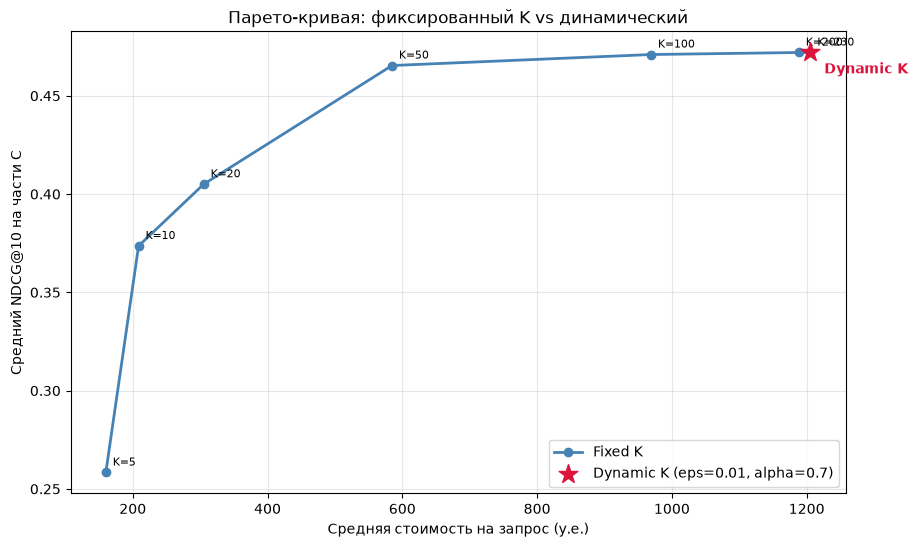

Сохранено: /home/piterburzhec/Work-Edu/ranking-project/figures/pareto_dynamic_vs_fixed.png


In [91]:
import matplotlib.pyplot as plt

# fixed_df уже есть из Дня 1 (reports/fixed_k_results.csv)
fixed_df = pd.read_csv(config.REPORTS / "fixed_k_results.csv")

# Усредняем динамику по части C
dyn_mean_ndcg = dynamic_results["ndcg@10"].mean()
dyn_mean_cost = dynamic_results["cost"].mean()

fig, ax = plt.subplots(figsize=(10, 6))

# Кривая фиксированных K
ax.plot(fixed_df["mean_cost"], fixed_df["mean_ndcg@10"],
        "o-", label="Fixed K", color="steelblue", linewidth=2)
for _, row in fixed_df.iterrows():
    ax.annotate(f"K={int(row['K'])}",
                (row["mean_cost"], row["mean_ndcg@10"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)

# Точка динамического K
ax.scatter([dyn_mean_cost], [dyn_mean_ndcg],
           s=200, marker="*", color="crimson",
           zorder=5, label=f"Dynamic K (eps=0.01, alpha=0.7)")

ax.annotate("Dynamic K",
            (dyn_mean_cost, dyn_mean_ndcg),
            textcoords="offset points", xytext=(10, -15),
            fontsize=10, color="crimson", fontweight="bold")

ax.set_xlabel("Средняя стоимость на запрос (у.е.)")
ax.set_ylabel("Средний NDCG@10 на части C")
ax.set_title("Парето-кривая: фиксированный K vs динамический")
ax.legend(loc="best")
ax.grid(True, alpha=0.3)

config.FIGURES.mkdir(parents=True, exist_ok=True)
out = config.FIGURES / "pareto_dynamic_vs_fixed.png"
plt.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("Сохранено:", out)

In [92]:
# 1) Что показывает динамическая точка vs фиксированная кривая
fixed_df = pd.read_csv(config.REPORTS / "fixed_k_results.csv")

dyn_ndcg = dynamic_results["ndcg@10"].mean()
dyn_cost = dynamic_results["cost"].mean()

print(f"Dynamic K: NDCG@10 = {dyn_ndcg:.4f}, cost = {dyn_cost:.1f}")
print("\nФиксированные K:")
print(fixed_df.to_string(index=False))

# Где бы мы были с фиксированным K при той же стоимости?
# Интерполируем NDCG фиксированной кривой в точке dyn_cost
from scipy.interpolate import interp1d
f = interp1d(fixed_df["mean_cost"], fixed_df["mean_ndcg@10"], kind="linear")
fixed_ndcg_at_dyn_cost = float(f(dyn_cost))
print(f"\nПри той же стоимости фиксированный K дал бы NDCG = {fixed_ndcg_at_dyn_cost:.4f}")
print(f"Разница: {dyn_ndcg - fixed_ndcg_at_dyn_cost:+.4f}")

Dynamic K: NDCG@10 = 0.4720, cost = 1205.5

Фиксированные K:
  K  mean_ndcg@10   mean_cost
  5      0.258344  160.057143
 10      0.373615  208.628571
 20      0.404993  305.200000
 50      0.465391  584.628571
100      0.470990  968.914286
200      0.472024 1188.342857
230      0.472024 1205.485714

При той же стоимости фиксированный K дал бы NDCG = 0.4720
Разница: +0.0000


In [93]:
k_map = dict(zip(predicted_k_df["query_id"], predicted_k_df["predicted_k"]))
...
# k = k_map.get(qid, max(config.K_GRID))  # fallback для «новых» запросов

Ellipsis

In [94]:
print("C qids в k_map:", sum(qid in k_map for qid in df_c["query_id"].unique()))
print("Всего qids в C:", df_c["query_id"].nunique())
# Ожидается 0 — вот и подтверждение

print("\nk_pred distribution в dynamic_results:")
print(dynamic_results["k_pred"].value_counts())
# Ожидается: 100% на одном значении (230)

C qids в k_map: 0
Всего qids в C: 35

k_pred distribution в dynamic_results:
k_pred
230    35
Name: count, dtype: int64


In [95]:
# 1) Все ли qids из C покрыты k_map?
k_map_c = dict(zip(predicted_k_c["query_id"], predicted_k_c["predicted_k"]))
n_missing = sum(qid not in k_map_c for qid in df_c["query_id"].unique())
print(f"qids C без предсказания: {n_missing} из {df_c['query_id'].nunique()}")
# Ожидание: 0. Если > 0 — Баг 1 всё ещё есть

# 2) Распределение предсказаний для C
print("\npredicted_k_c value_counts:")
print(predicted_k_c["predicted_k"].value_counts().sort_index())

# 3) Распределение таргета на B
print("\ntarget_eps_0.01 на B:")
print(targets_df["target_eps_0.01"].value_counts().sort_index())

# 4) Loss@K для B — почему таргет такой
targets_df["loss_at_100"] = targets_df["ndcg_full"] - targets_df["ndcg_at_100"]
targets_df["loss_at_200"] = targets_df["ndcg_full"] - targets_df["ndcg_at_200"]
print(f"\nLoss@K=100: mean={targets_df['loss_at_100'].mean():.4f}, "
      f">0.01 у {(targets_df['loss_at_100'] > 0.01).mean():.1%} запросов")
print(f"Loss@K=200: mean={targets_df['loss_at_200'].mean():.4f}, "
      f">0.01 у {(targets_df['loss_at_200'] > 0.01).mean():.1%} запросов")

qids C без предсказания: 0 из 35

predicted_k_c value_counts:
predicted_k
20    28
30     7
Name: count, dtype: int64

target_eps_0.01 на B:
target_eps_0.01
5      6
10     9
20     9
30     3
50     1
75     3
100    1
150    2
Name: count, dtype: int64

Loss@K=100: mean=0.0024, >0.01 у 5.9% запросов
Loss@K=200: mean=0.0000, >0.01 у 0.0% запросов


In [96]:
dynamic_results = apply_dynamic_k(
    df_c, cheap_ranker, expensive_ranker,
    cheap_features, all_features,
    predicted_k_c,   # ← именно C, не df
)

# Sanity-check: k_pred должен совпасть с predicted_k_c
merged_check = dynamic_results.merge(predicted_k_c, on="query_id")
assert (merged_check["k_pred"] == merged_check["predicted_k"]).all(), \
    "k_pred в dynamic_results не совпадает с predicted_k_c"
print("OK:", dynamic_results["k_pred"].value_counts().sort_index())

OK: k_pred
20    28
30     7
Name: count, dtype: int64


In [97]:
print("k_pred в dynamic_results:")
print(dynamic_results["k_pred"].value_counts().sort_index())

k_pred в dynamic_results:
k_pred
20    28
30     7
Name: count, dtype: int64
